# Prédiction du nombre de décès (EM-DAT) : régression Random Forest

**Objectif** : Prédire le nombre de décès d'une catastrophe (échelle logarithmique) à partir de son type, de sa localisation, de sa date et de deux indicateurs économiques et démographiques.

**Données**

- `public_emdat_project.csv` : EM-DAT (CRED), non redistribué dans ce dépôt.
- `population_density.csv` et `gdp_per_capita.csv` : indicateurs de la Banque Mondiale (densité de population, PIB par habitant), au format « données par pays ».
- Source et licence : voir les sections Source et Licence du README.

**Exécution** : installer les dépendances (`pip install -r requirements.txt`), puis lancer « Restart & Run All » depuis la racine du dépôt.


In [1]:
from pathlib import Path

FICHIERS_ATTENDUS = ['public_emdat_project.csv', 'population_density.csv', 'gdp_per_capita.csv']
manquants = [f for f in FICHIERS_ATTENDUS if not Path(f).exists()]
if manquants:
    raise FileNotFoundError(f"Fichiers manquants : {manquants}. Voir la section « Données » du README.")
print('Fichiers présents :', FICHIERS_ATTENDUS)


Fichiers présents : ['public_emdat_project.csv', 'population_density.csv', 'gdp_per_capita.csv']


In [2]:
# Import
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.ensemble import RandomForestRegressor
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
df = pd.read_csv("public_emdat_project.csv", encoding="ISO-8859-1")
df.dtypes

DisNo.                                           str
Historic                                         str
Classification Key                               str
Disaster Group                                   str
Disaster Subgroup                                str
Disaster Type                                    str
Disaster Subtype                                 str
External IDs                                     str
Event Name                                       str
ISO                                              str
Country                                          str
Subregion                                        str
Region                                           str
Location                                         str
Origin                                           str
Associated Types                                 str
OFDA/BHA Response                                str
Appeal                                           str
Declaration                                   

In [4]:
df = df.dropna(subset=['Total Deaths'])
df = df[['Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'Subregion', 'Start Year', 'Start Month', 'CPI', 'Magnitude', 'ISO', 'Total Deaths']]
type(df)

pandas.DataFrame

In [5]:
# enrichissement : densité de population
# Charger fichier (skiprows=4 pour sauter l'en-tête Banque Mondiale)
df_pop = pd.read_csv("population_density.csv", skiprows=4)

# Garder uniquement les colonnes utiles : code pays + années
df_pop = df_pop.drop(columns=["Country Name", "Indicator Name", "Indicator Code", "Unnamed: 70"])

# Pivoter : passer de wide à long
df_pop = df_pop.melt(
    id_vars=["Country Code"],       # colonne qui reste fixe
    var_name="year",                # les colonnes années deviennent une colonne "year"
    value_name="population_density" # les valeurs deviennent "population_density"
)

df_pop["year"] = pd.to_numeric(df_pop["year"], errors="coerce") # convert to number
df_pop = df_pop.dropna(subset=["year"])                         # drop not number
df_pop["year"] = df_pop["year"].astype(int)                     # conversion float to integer

print(df_pop.dtypes)
print(df_pop.shape)

Country Code              str
year                    int64
population_density    float64
dtype: object
(17556, 3)


In [6]:
# Charger le fichier PIB par habitant (Banque Mondiale)
df_pib = pd.read_csv("gdp_per_capita.csv", skiprows=4)

# Supprimer les colonnes inutiles
df_pib = df_pib.drop(columns=["Country Name", "Indicator Name", "Indicator Code", "Unnamed: 70"])

# Pivoter : passer de wide à long
df_pib = df_pib.melt(
    id_vars=["Country Code"],
    var_name="year",
    value_name="gdp_per_capita"
)

# Convertir l'année en entier
df_pib["year"] = pd.to_numeric(df_pib["year"], errors="coerce")
df_pib = df_pib.dropna(subset=["year"])
df_pib["year"] = df_pib["year"].astype(int)

print(df_pib.dtypes)
print("Non-null gdp:", df_pib["gdp_per_capita"].notna().sum())

print(df_pib.dtypes)
print(df_pib.shape)

Country Code          str
year                int64
gdp_per_capita    float64
dtype: object
Non-null gdp: 14561
Country Code          str
year                int64
gdp_per_capita    float64
dtype: object
(17556, 3)


In [7]:
# Merge densité de population
df = df.merge(df_pop, left_on=["ISO", "Start Year"], right_on=["Country Code", "year"], how="left")

# Merge PIB par habitant
df = df.merge(df_pib, left_on=["ISO", "Start Year"], right_on=["Country Code", "year"], how="left",
              suffixes=("", "_pib"))  # évite les conflits de noms de colonnes

In [8]:
df.dtypes

Disaster Subgroup         str
Disaster Type             str
Disaster Subtype          str
Subregion                 str
Start Year              int64
Start Month           float64
CPI                   float64
Magnitude             float64
ISO                       str
Total Deaths          float64
Country Code              str
year                  float64
population_density    float64
Country Code_pib          str
year_pib              float64
gdp_per_capita        float64
dtype: object

In [9]:
import plotly.express as px

px.scatter_3d(data_frame=df, x="Disaster Subtype", y="Subregion", z="Total Deaths", color="Disaster Type")

In [10]:
df.describe(include='all')

,Disaster Subgroup,Disaster Type,Disaster Subtype,Subregion,Start Year,Start Month,CPI,Magnitude,ISO,Total Deaths,Country Code,year,population_density,Country Code_pib,year_pib,gdp_per_capita
count,12655,12655,12655,12655,12655.000000,12636.000000,12532.000000,2.602000e+03,12655,12655.000000,12540,12540.000000,12350.000000,12540,12540.000000,12464.000000
unique,8,29,59,17,NaN,NaN,NaN,NaN,213,NaN,201,NaN,NaN,201,NaN,NaN
top,Transport,Flood,Road,Sub-Saharan Africa,NaN,NaN,NaN,NaN,CHN,NaN,CHN,NaN,NaN,CHN,NaN,NaN
freq,3873,2959,2119,2831,NaN,NaN,NaN,NaN,1173,NaN,1173,NaN,NaN,1173,NaN,NaN
mean,NaN,NaN,NaN,NaN,2010.478941,6.502928,72.540589,6.956993e+04,NaN,135.976847,NaN,2010.487241,167.449245,NaN,2010.487241,8613.189256
std,NaN,NaN,NaN,NaN,7.052313,3.413547,11.384091,8.420944e+05,NaN,3088.333299,NaN,7.050641,355.499328,NaN,7.050641,14851.646322
min,NaN,NaN,NaN,NaN,2000.000000,1.000000,56.514291,-5.700000e+01,NaN,0.000000,NaN,2000.000000,1.543388,NaN,2000.000000,109.593814
25%,NaN,NaN,NaN,NaN,2004.000000,4.000000,61.989586,3.600000e+01,NaN,9.000000,NaN,2004.000000,37.971137,NaN,2004.000000,986.674011
50%,NaN,NaN,NaN,NaN,2010.000000,7.000000,71.563596,2.135000e+02,NaN,16.000000,NaN,2010.000000,97.701323,NaN,2010.000000,2383.918925
75%,NaN,NaN,NaN,NaN,2016.000000,9.000000,78.767923,2.497756e+04,NaN,32.000000,NaN,2016.000000,195.404660,NaN,2016.000000,7814.535149


In [11]:
df.isnull().sum()

Disaster Subgroup         0
Disaster Type             0
Disaster Subtype          0
Subregion                 0
Start Year                0
Start Month              19
CPI                     123
Magnitude             10053
ISO                       0
Total Deaths              0
Country Code            115
year                    115
population_density      305
Country Code_pib        115
year_pib                115
gdp_per_capita          191
dtype: int64

In [12]:
# separating features X from target y
features_list = ['Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'Subregion', 'Start Year', 'Start Month', 'CPI', 'Magnitude', 'population_density', 'gdp_per_capita']

X = df.loc[:, features_list]
y = df.loc[:, "Total Deaths"]

y = np.log1p(y)     # On utilise log1p (log de 1+x) pour éviter l'erreur sur les valeurs à 0 morts

print(X.shape, y.shape)     
print(type(X), type(y))

(12655, 10) (12655,)
<class 'pandas.DataFrame'> <class 'pandas.Series'>


In [13]:
# separating dataset into training set and test set
from sklearn.model_selection import train_test_split

# splitting both dataframes with 20% of size and random state for shuffling data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)    # stratify permet de conserver proportion dans les splits

In [14]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape     # checking splitted dataframes shapes

((10124, 10), (2531, 10), (10124,), (2531,))

In [15]:
X_train.dtypes    # X_train values before preprocessing

Disaster Subgroup         str
Disaster Type             str
Disaster Subtype          str
Subregion                 str
Start Year              int64
Start Month           float64
CPI                   float64
Magnitude             float64
population_density    float64
gdp_per_capita        float64
dtype: object

In [16]:
# Copy X_train to avoid caveats
X_train = X_train.copy()

numerical_imputer = SimpleImputer(strategy="median")
X_train[["Start Year", "Start Month", "CPI", "Magnitude", "population_density", "gdp_per_capita"]] = numerical_imputer.fit_transform(X_train[["Start Year", "Start Month", "CPI", "Magnitude", "population_density", "gdp_per_capita"]])

categorical_imputer = SimpleImputer(strategy="constant", fill_value="Unknown")
X_train[["Disaster Subgroup", "Disaster Type", "Disaster Subtype", "Subregion"]] = categorical_imputer.fit_transform(X_train[["Disaster Subgroup", "Disaster Type", "Disaster Subtype", "Subregion"]])

X_train.isnull().any()


Disaster Subgroup     False
Disaster Type         False
Disaster Subtype      False
Subregion             False
Start Year            False
Start Month           False
CPI                   False
Magnitude             False
population_density    False
gdp_per_capita        False
dtype: bool

In [17]:
# numerical features normalization (scaling X_train)

numeric_features = [4, 5, 6, 7, 8, 9]
numeric_transformer = StandardScaler()

In [18]:
# categorical features encoding

categorical_features = [0, 1, 2, 3] 
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

In [19]:
# applying the preprocessing to the dataset

feature_encoder = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features),
        ('num', numeric_transformer, numeric_features)
        ]
    )

In [20]:
# finalizing preprocessing by fitting and transforming X_train

X_train = feature_encoder.fit_transform(X_train)   

In [21]:
print(X_train[0:5,:])       # X_train after preprocessing, different from X_train before

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 50 stored elements and shape (5, 119)>
  Coords	Values
  (0, 5)	1.0
  (0, 33)	1.0
  (0, 90)	1.0
  (0, 108)	1.0
  (0, 113)	-1.0581794595901197
  (0, 114)	-0.7420652504308437
  (0, 115)	-1.0705193811167788
  (0, 116)	-0.03592089389021182
  (0, 117)	0.7398916524243037
  (0, 118)	-0.5369530353767251
  (1, 7)	1.0
  (1, 35)	1.0
  (1, 94)	1.0
  (1, 107)	1.0
  (1, 113)	-0.6338682726093573
  (1, 114)	-1.6274363136805916
  (1, 115)	-0.5612761117698896
  (1, 116)	-0.03563828691541634
  (1, 117)	-0.13091952063082143
  (1, 118)	-0.46838014997576194
  (2, 7)	1.0
  (2, 32)	1.0
  (2, 80)	1.0
  (2, 100)	1.0
  (2, 113)	0.2147541013521675
  (2, 114)	-0.15181787493101173
  (2, 115)	0.24741741543303117
  (2, 116)	-0.03563828691541634
  (2, 117)	-0.48310689181124583
  (2, 118)	-0.1329397791289668
  (3, 3)	1.0
  (3, 21)	1.0
  (3, 45)	1.0
  (3, 108)	1.0
  (3, 113)	-0.49243121028243647
  (3, 114)	0.7335531883187362
  (3, 115)	-0.3951963371866236
  (

In [22]:
# training model

Regressor = RandomForestRegressor(
    n_estimators=100, 
    max_depth=15,         # Limite la complexité de chaque arbre
    min_samples_leaf=5,  # Chaque "feuille" doit contenir au moins 5 exemples
    random_state=42
)
Regressor.fit(X_train, y_train.values.ravel()) # training the model, finding coefficients and intercepts

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

In [23]:
y_train_pred = Regressor.predict(X_train)   # Predictions on training set

In [24]:
# Testing pipeline: same preprocessing for X_test as for X_train

X_test = X_test.copy()

# Imputing (again, this time for X_test)
X_test[["Start Year", "Start Month", "CPI", "Magnitude", "population_density", "gdp_per_capita"]] = numerical_imputer.transform(X_test[["Start Year", "Start Month", "CPI", "Magnitude", "population_density", "gdp_per_capita"]])
X_test[["Disaster Subgroup", "Disaster Type", "Disaster Subtype", "Subregion"]] = categorical_imputer.transform(X_test[["Disaster Subgroup", "Disaster Type", "Disaster Subtype", "Subregion"]])

# Standardizing numeric features (no categorical features)
print("X_test before preprocessing (types) :", X_test.dtypes)

X_test = feature_encoder.transform(X_test)
print("X_test after preprocessing:", X_test[:5])

# Predictions on test set
y_test_pred = Regressor.predict(X_test)
print("Predictions y_test:", y_test_pred[:5])

X_test before preprocessing (types) : Disaster Subgroup         str
Disaster Type             str
Disaster Subtype          str
Subregion                 str
Start Year            float64
Start Month           float64
CPI                   float64
Magnitude             float64
population_density    float64
gdp_per_capita        float64
dtype: object
X_test after preprocessing: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 50 stored elements and shape (5, 119)>
  Coords	Values
  (0, 7)	1.0
  (0, 35)	1.0
  (0, 94)	1.0
  (0, 111)	1.0
  (0, 113)	-0.9167423972631988
  (0, 114)	1.3238005638185681
  (0, 115)	-0.9282874228573385
  (0, 116)	-0.03563828691541634
  (0, 117)	-0.25401323182175783
  (0, 118)	-0.16943633141796408
  (1, 5)	1.0
  (1, 18)	1.0
  (1, 46)	1.0
  (1, 108)	1.0
  (1, 113)	-1.0581794595901197
  (1, 114)	1.618924251568484
  (1, 115)	-1.0705193811167788
  (1, 116)	-0.03563828691541634
  (1, 117)	3.193763893765868
  (1, 118)	-0.5448906078349472
  (2, 6)	1.0
  (2, 2

In [25]:
# Performance assessment

print("Score on training set: ", Regressor.score(X_train, y_train))
print("Score on test set: ", Regressor.score(X_test, y_test))

Score on training set:  0.5238234471715879
Score on test set:  0.25107661060844855


In [26]:
print("All transformers are: ", feature_encoder.transformers_)
# underscore signifie attribut non préexistant, mais créé par la classe ColumnTransformer pendant le fit_transform

print("One Hot Encoder transformer is: ", feature_encoder.transformers_[0][1])
# double indexage : 0 pour le premier de liste transformer (cat), 1 pour accéder à l'instance de OneHotEncoder

categorical_column_names = feature_encoder.transformers_[0][1].categories_
print("Categorical columns are: ", categorical_column_names)

numerical_column_names = X.iloc[:, numeric_features].columns
print("numerical columns are: ", numerical_column_names)

# 1. Récupérer TOUS les noms de colonnes transformées d'un seul coup
# Cette fonction gère l'ordre, les préfixes (cat__, num__) et le drop='first'
all_column_names = feature_encoder.get_feature_names_out()

# 2. Créer le DataFrame d'importance
# Si Regressor.coef_ est en 2D (ex: [[0.1, 0.2]]), on utilise .flatten()
feature_importance = pd.DataFrame({
    "feature_names": all_column_names,
    "coefficients": Regressor.feature_importances_
})

# 3. Passer en valeur absolue
feature_importance["coefficients"] = feature_importance["coefficients"].abs()


All transformers are:  [('cat', OneHotEncoder(handle_unknown='ignore'), [0, 1, 2, 3]), ('num', StandardScaler(), [4, 5, 6, 7, 8, 9])]
One Hot Encoder transformer is:  OneHotEncoder(handle_unknown='ignore')
Categorical columns are:  [array(['Biological', 'Climatological', 'Geophysical', 'Hydrological',
       'Industrial accident', 'Meteorological', 'Miscellaneous accident',
       'Transport'], dtype=object), array(['Air', 'Animal incident', 'Chemical spill',
       'Collapse (Industrial)', 'Collapse (Miscellaneous)', 'Drought',
       'Earthquake', 'Epidemic', 'Explosion (Industrial)',
       'Explosion (Miscellaneous)', 'Extreme temperature',
       'Fire (Industrial)', 'Fire (Miscellaneous)', 'Flood', 'Gas leak',
       'Glacial lake outburst flood', 'Industrial accident (General)',
       'Mass movement (dry)', 'Mass movement (wet)',
       'Miscellaneous accident (General)', 'Oil spill', 'Poisoning',
       'Radiation', 'Rail', 'Road', 'Storm', 'Volcanic activity', 'Water',
      

In [27]:
# Check feature importances (Random Forest n'a pas de coef_ ni intercept_)
print("Feature importances: ", Regressor.feature_importances_)

# Access transformers from feature_encoder
print("All transformers are: ", feature_encoder.transformers_)
print("One Hot Encoder transformer is: ", feature_encoder.transformers_[0][1])

# Print categories
categorical_column_names = feature_encoder.transformers_[0][1].categories_

flat_cat_features = np.array([cat for sublist in categorical_column_names for cat in sublist])
print("Categorical columns are: ", flat_cat_features)

numerical_column_names = X.iloc[:, numeric_features].columns
print("numerical columns are: ", numerical_column_names)

all_column_names = np.append(flat_cat_features, numerical_column_names)
print("All column names are: ", all_column_names)

Feature importances:  [5.26824984e-03 2.09978663e-03 1.57391853e-03 2.21196739e-03
 2.53238467e-03 5.34130068e-03 6.05558477e-03 3.59143509e-02
 6.81158258e-04 0.00000000e+00 2.04690423e-05 1.09014070e-04
 2.44479903e-05 8.16428267e-05 2.65590936e-03 2.04996904e-02
 2.33375065e-04 8.45192404e-05 1.41374993e-02 8.44799747e-06
 5.94274419e-04 3.70700176e-02 8.15469109e-05 0.00000000e+00
 1.05547597e-05 0.00000000e+00 9.07068592e-04 2.47150301e-04
 0.00000000e+00 0.00000000e+00 0.00000000e+00 4.88803248e-04
 2.08743618e-03 3.51234311e-02 0.00000000e+00 5.95515957e-03
 5.29291662e-03 7.15887635e-04 0.00000000e+00 2.57156951e-04
 0.00000000e+00 1.28363156e-04 1.50305375e-03 2.09695494e-03
 1.01267614e-05 0.00000000e+00 1.52775714e-03 1.00041194e-04
 3.57616530e-05 0.00000000e+00 1.81568499e-06 1.22812027e-04
 3.05509010e-05 2.01381073e-04 2.27799051e-05 4.47111147e-04
 2.56545995e-03 3.28310434e-03 1.39428613e-03 1.60080261e-04
 0.00000000e+00 4.26404351e-03 0.00000000e+00 6.09995819e-02
 1

In [28]:
import plotly.express as px

# 1. On ne garde que les 15 variables les plus importantes
df_plot = feature_importance.sort_values(by="coefficients", ascending=False).head(15)

# 2. Création du graphique (on passe en horizontal pour plus de lisibilité)
fig = px.bar(
    df_plot, 
    x="coefficients",        # Inversion x et y
    y="feature_names", 
    orientation='h',         # Barre horizontale : plus facile de lire les noms
    title="Top 15 des caractéristiques les plus importantes",
    labels={"feature_names": "Variables", "coefficients": "Importance (Abs)"},
    color="coefficients",
    color_continuous_scale="Viridis"
)

# 3. On ajuste la mise en page
fig.update_layout(
    yaxis={'categoryorder':'total ascending'}, # Trie les barres de la plus grande à la plus petite
    template="plotly_dark",
    height=600  # On réduit un peu la hauteur puisqu'il y a moins de barres
)

fig.show()

In [29]:
from sklearn.metrics import mean_absolute_error

# Prédictions dans l'espace log
y_pred_log = Regressor.predict(X_test)

# Retour à l'échelle réelle
y_pred_real = np.expm1(y_pred_log)
y_test_real = np.expm1(y_test)

# MAE en nombre de morts réels
mae = mean_absolute_error(y_test_real, y_pred_real)
print(f"MAE : {mae:.0f} morts")

MAE : 196 morts


In [30]:
import numpy as np
erreurs = np.abs(y_test_real - y_pred_real)
print(f"Erreur médiane : {np.median(erreurs):.0f} morts")
print(f"Erreur au 75e percentile : {np.percentile(erreurs, 75):.0f} morts")

Erreur médiane : 9 morts
Erreur au 75e percentile : 20 morts


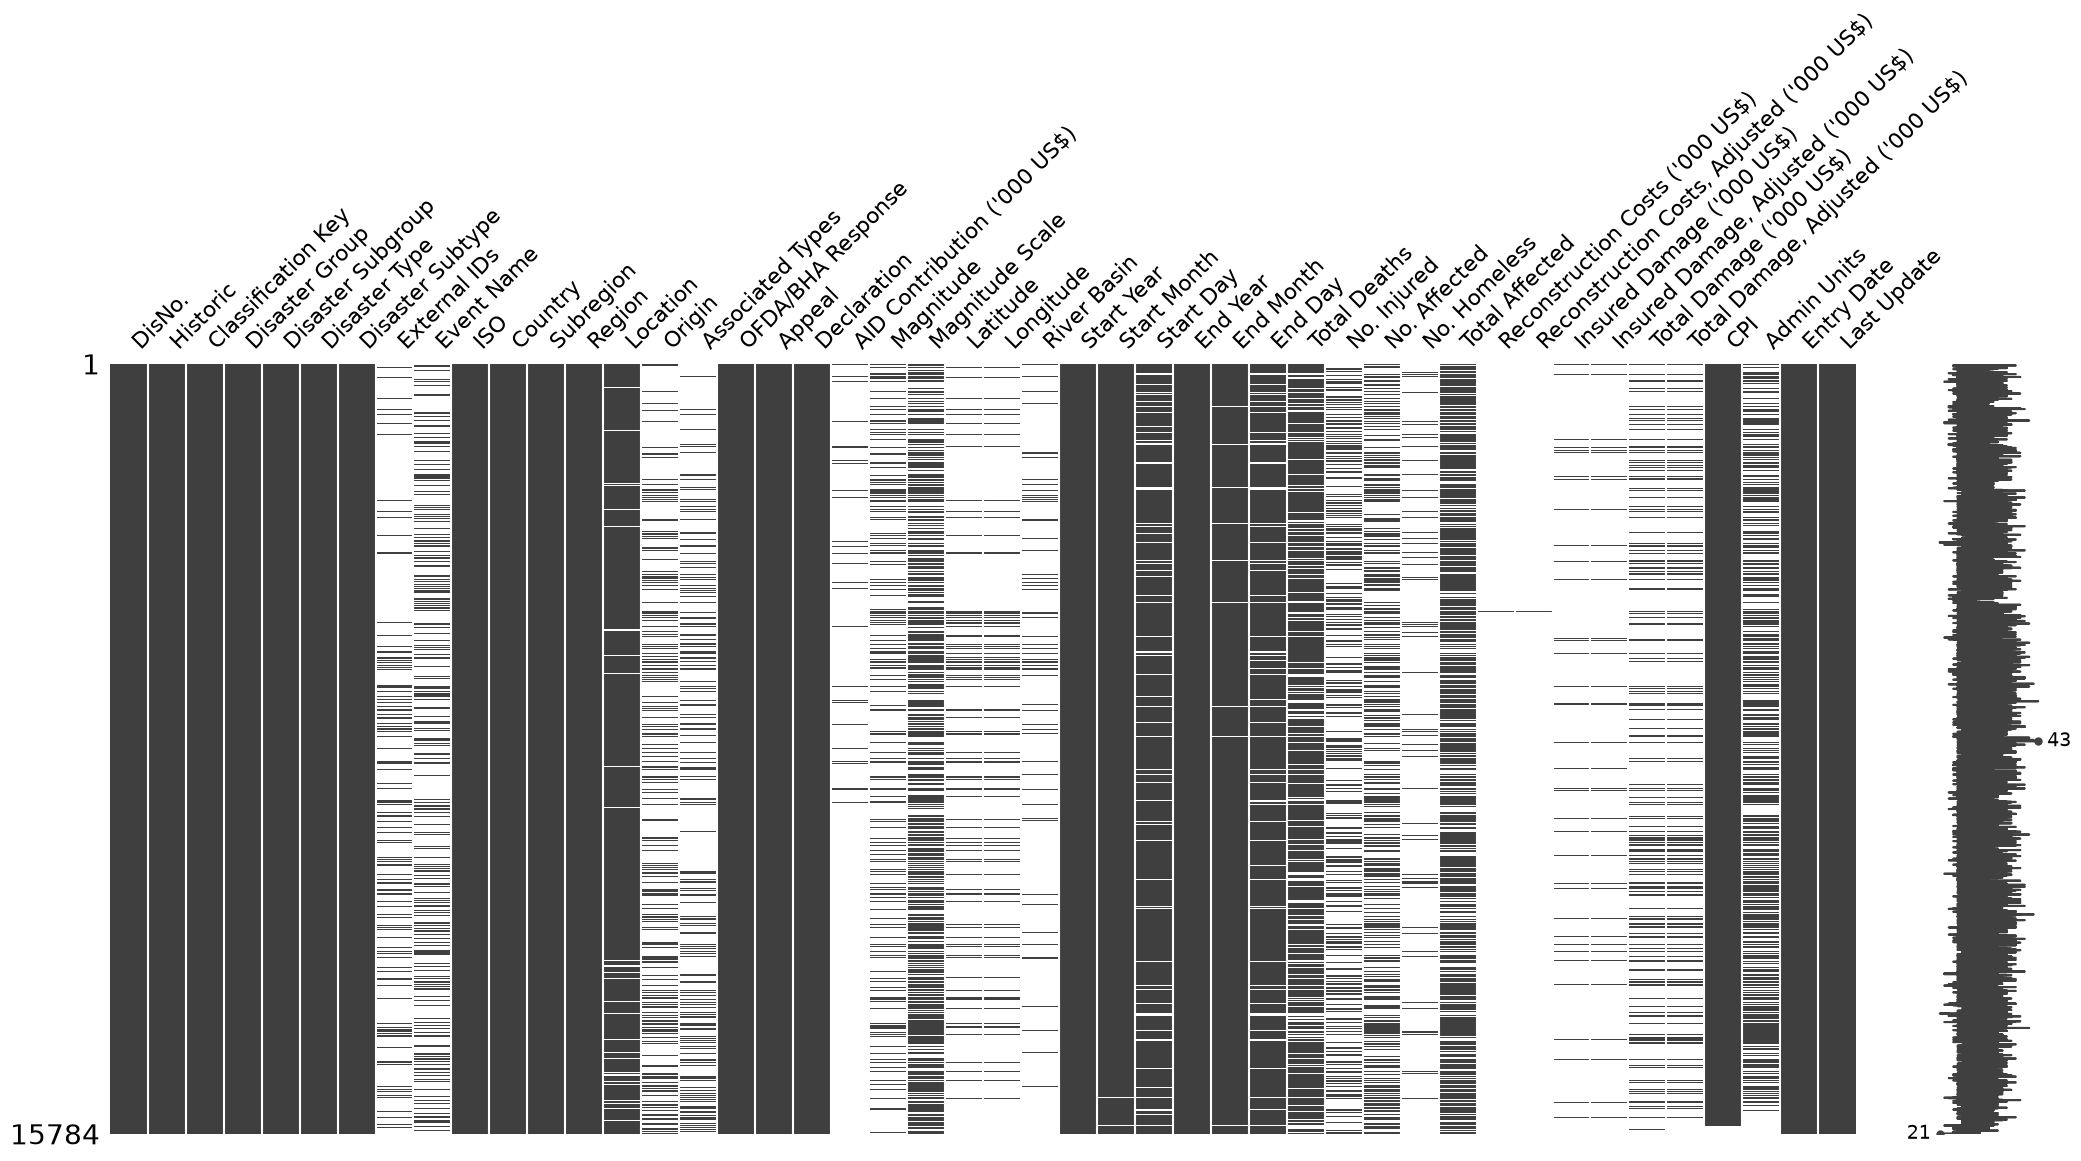

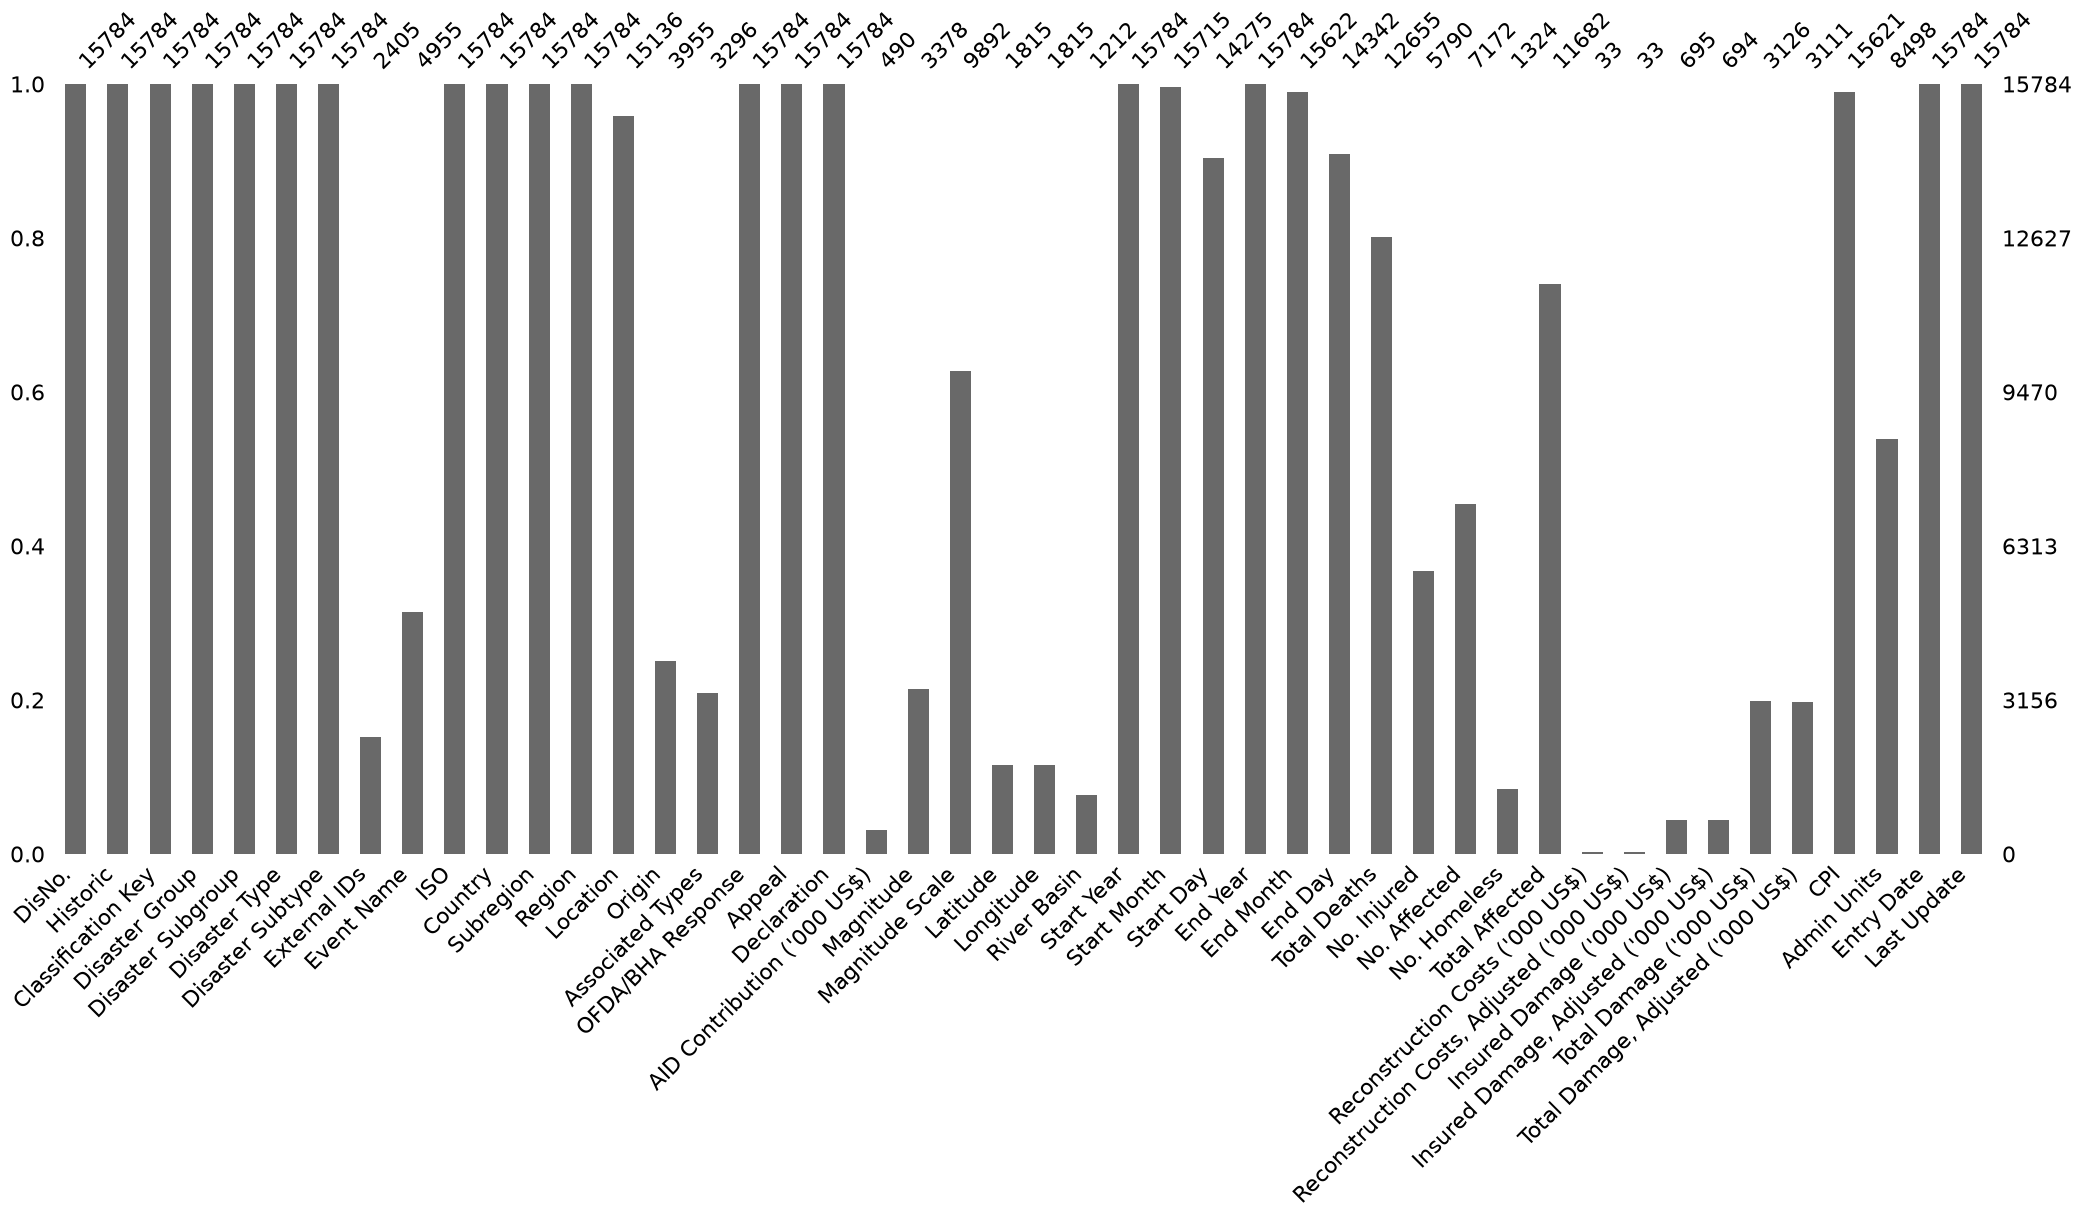

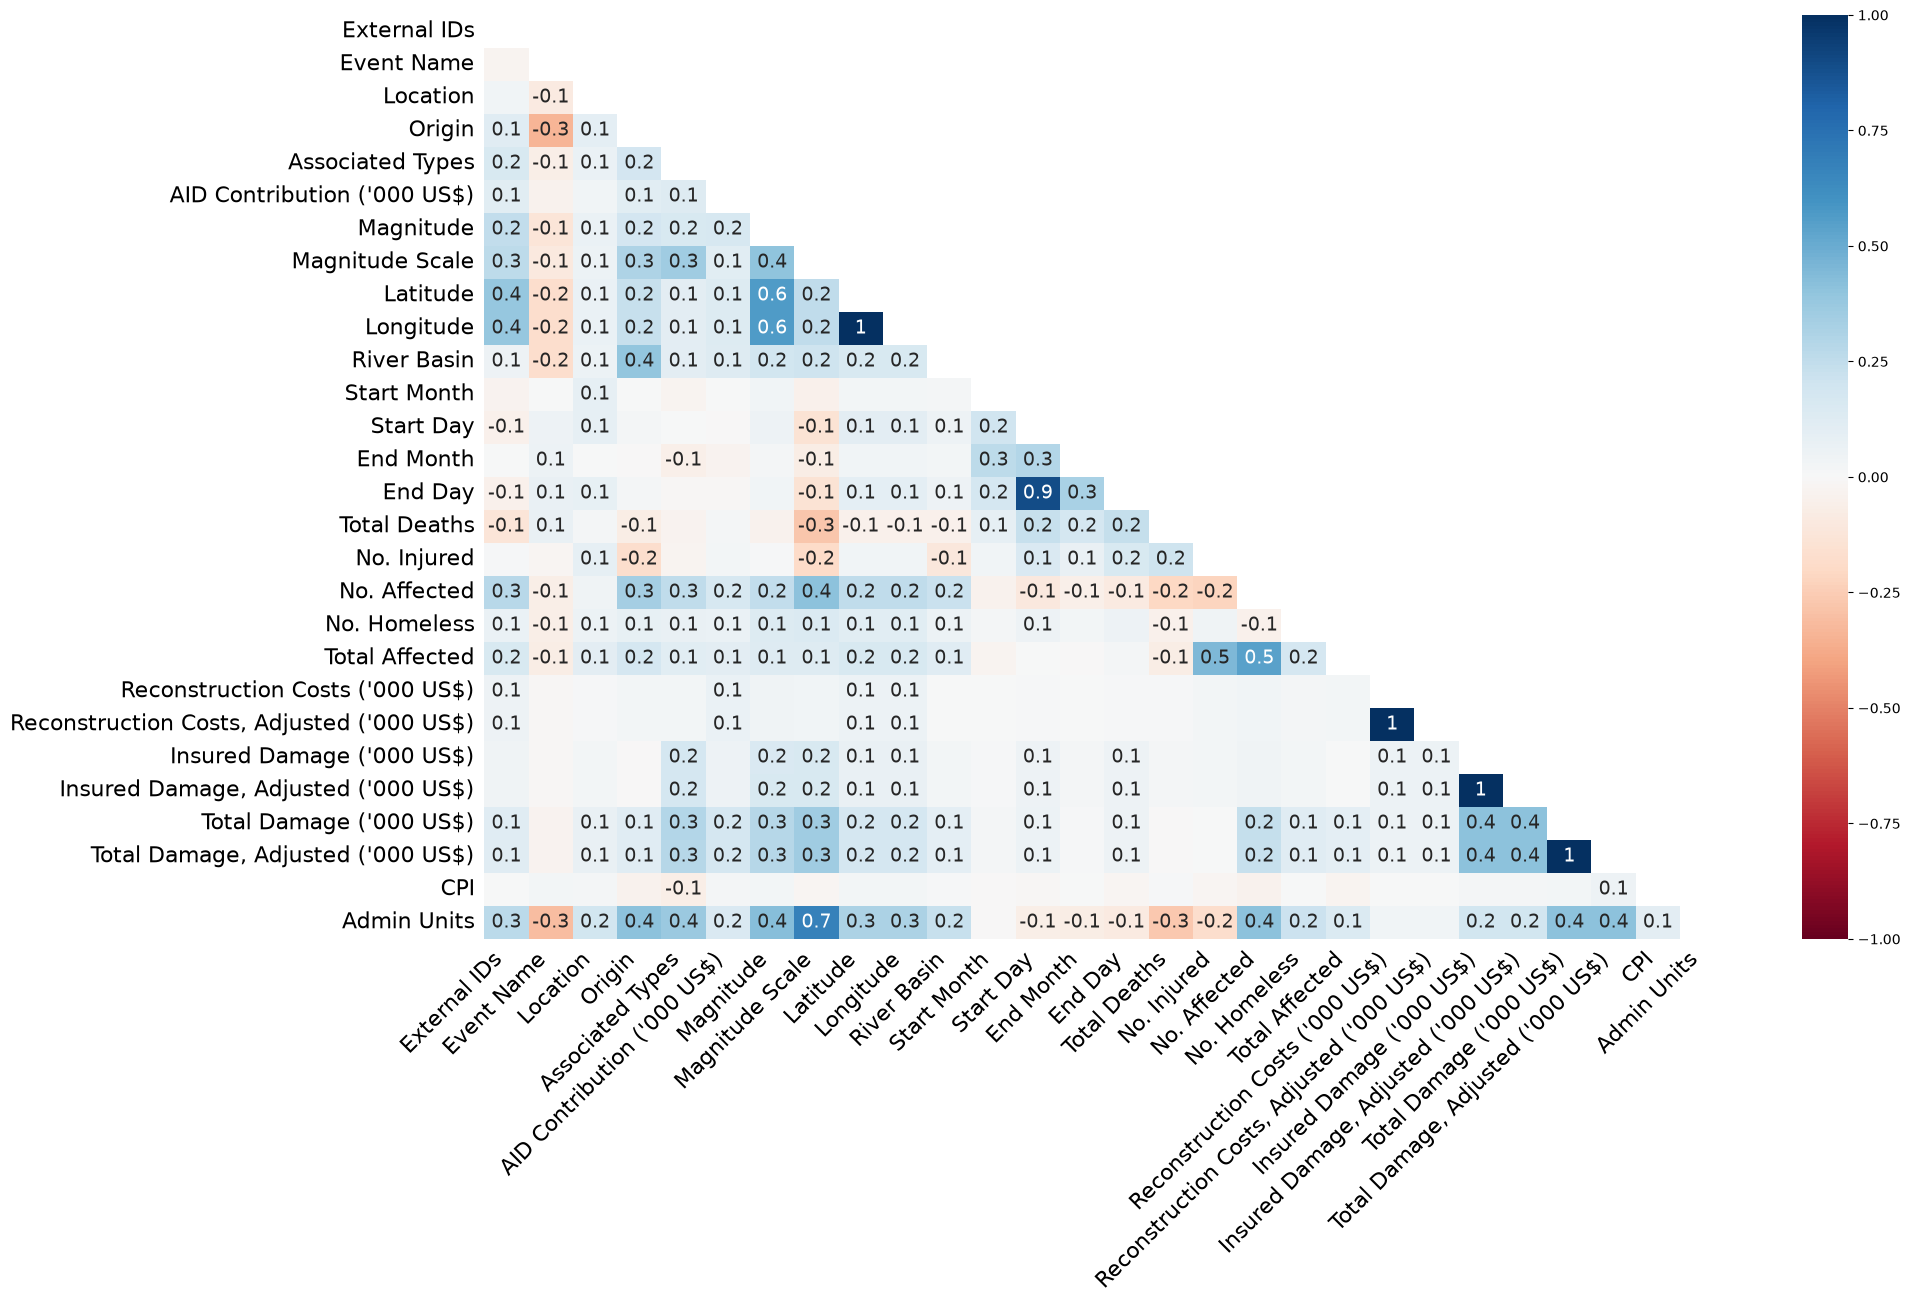

In [31]:

import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt

# Charger les données
df = pd.read_csv('public_emdat_project.csv', encoding="ISO-8859-1")

# 1. La Matrice (msno.matrix) : Idéal pour voir si les "trous" sont regroupés
msno.matrix(df)
plt.show()

# 2. Le graphique à barres (msno.bar) : Pour voir le % de complétion par colonne
msno.bar(df)
plt.show()

# 3. Le Heatmap de corrélation (msno.heatmap) : 
# Pour savoir si l'absence d'une donnée (ex: Morts) est liée à l'absence d'une autre (ex: Dommages)
msno.heatmap(df)
plt.show()

## Interprétation et limites

**Performance.** Le R² est de 0,524 sur le train et de 0,251 sur le test (cellule `Score on test set`). Cet écart indique un surapprentissage : le modèle mémorise plus qu'il ne généralise.

**Erreur.** L'erreur absolue moyenne est de 196 décès, alors que l'erreur médiane est de 9 et l'erreur au 75e percentile de 20 (cellules `MAE` et `Erreur médiane`). L'erreur typique est donc faible, mais la moyenne est dominée par quelques cas extrêmes. Le modèle semble moins fiable pour les grandes catastrophes ; cette hypothèse reste à vérifier, par exemple en calculant l'erreur par tranche de décès.

**Données manquantes.** `Magnitude` est absente pour 10 053 des 12 655 lignes retenues (cellule `df.isnull().sum()`), soit environ 79 %. Elle est imputée par la médiane : son importance doit être lue avec prudence, d'autant que ses unités changent selon le type de catastrophe.

**Variables.** Les importances sont affichées sous forme de tableau brut (cellule `Feature importances`), sans noms de variables. Le graphique « Top 15 » donne les noms : c'est lui qu'il faut lire pour identifier les variables dominantes.

**Limites.**
- Hyperparamètres fixés à la main (profondeur 15, 100 arbres) : aucune recherche sur grille ni validation croisée.
- Un seul découpage 80/20 : les résultats peuvent varier d'un découpage à l'autre.
- Données observationnelles : le modèle associe des variables, il n'établit pas de causalité.
- Les lignes sans code pays (115) ont des indicateurs économiques et démographiques imputés par la médiane.
